In [1]:
import pyarrow.parquet as pq
import s3fs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
%matplotlib inline

In [2]:
fileSystem = s3fs.S3FileSystem()
bucket_name="aws-acc-001-1053-r42-offlinemapmatch/output/speed/parquet/year=2019/month=1/day=11"
df = pq.ParquetDataset("s3://" + bucket_name, filesystem=fileSystem).read().to_pandas()

In [3]:
df['from_node'] = pd.to_numeric(df['from_node'])
df['to_node'] = pd.to_numeric(df['to_node'])
df['hour'] = df['timestamp'].apply(lambda s: datetime.fromtimestamp(s).strftime("%H"))
df['hour'] = pd.to_numeric(df['hour'])
df.head()

,booking_id,estimated_speed,timestamp,from_node,to_node,map_id,speed_estimator_id,city_name,source,metadata,speed_unit,partition,minute,dayofweek,hour
0,7083172fbbc22c9241c2df234f566af9ee0e9c1b,5.830082,1547212498,29266379,29266394,osm,version_1,Berlin,offlinemapmatcher-spark,"{'id': '2130303778857', 'created_timestamp': 1...",m/s,OK,14,6,14
1,0f9c52a966dd2c68c03390137df1773753a434d4,5.033316,1547218007,1803835434,310350615,osm,version_1,Berlin,offlinemapmatcher-spark,"{'id': '1460288880702', 'created_timestamp': 1...",m/s,OK,46,6,15
2,7083172fbbc22c9241c2df234f566af9ee0e9c1b,5.830082,1547212498,29266394,1368445831,osm,version_1,Berlin,offlinemapmatcher-spark,"{'id': '2130303778857', 'created_timestamp': 1...",m/s,OK,14,6,14
3,0f9c52a966dd2c68c03390137df1773753a434d4,5.033316,1547218007,310350615,2081684385,osm,version_1,Berlin,offlinemapmatcher-spark,"{'id': '1460288880702', 'created_timestamp': 1...",m/s,OK,46,6,15
4,7083172fbbc22c9241c2df234f566af9ee0e9c1b,5.830082,1547212498,1368445831,6206155587,osm,version_1,Berlin,offlinemapmatcher-spark,"{'id': '2130303778857', 'created_timestamp': 1...",m/s,OK,14,6,14


In [4]:
from jurbey.jurbey import JURBEY
with open('../data/1558537930325.jurbey', 'rb') as f:
    g = JURBEY.load(f.read())

In [5]:
nodes = pd.DataFrame({'nodes': list(g.nodes())})
nodes['lat'] = nodes['nodes'].apply(lambda x: g.nodes[x]['data'].coord.lat)
nodes['lon'] = nodes['nodes'].apply(lambda x: g.nodes[x]['data'].coord.lon)
nodes.head()

,nodes,lat,lon
0,1234120411,52.373418,13.605168
1,6375730236,52.373500,13.605500
2,262876417,52.373662,13.606160
3,262877047,52.373981,13.607399
4,21432146,52.374028,13.607555


In [6]:
def merge_coord(df, nodes, left_on, rename):
    df = pd.merge(df, nodes, how='left', left_on=left_on, right_on='nodes')
    df.dropna(inplace=True)
    df['coord'] = list(zip(df.lon, df.lat))
    df.rename(columns={'coord':rename}, inplace=True)
    df.drop(columns=['nodes', 'lat', 'lon'], inplace=True)
    
    return df

df = merge_coord(df, nodes, left_on='from_node', rename='from_coord')
df = merge_coord(df, nodes, left_on='to_node', rename='to_coord')
df.drop(columns=['map_id', 'speed_estimator_id', 'source', 'partition'], inplace=True)
df.head()

,booking_id,estimated_speed,timestamp,from_node,to_node,city_name,metadata,speed_unit,minute,dayofweek,hour,from_coord,to_coord
0,7083172fbbc22c9241c2df234f566af9ee0e9c1b,5.830082,1547212498,29266379,29266394,Berlin,"{'id': '2130303778857', 'created_timestamp': 1...",m/s,14,6,14,"(13.4303742, 52.5311009)","(13.4283397, 52.5319418)"
1,0f9c52a966dd2c68c03390137df1773753a434d4,5.033316,1547218007,1803835434,310350615,Berlin,"{'id': '1460288880702', 'created_timestamp': 1...",m/s,46,6,15,"(13.3849402, 52.5310726)","(13.3837551, 52.5307473)"
2,7083172fbbc22c9241c2df234f566af9ee0e9c1b,5.830082,1547212498,29266394,1368445831,Berlin,"{'id': '2130303778857', 'created_timestamp': 1...",m/s,14,6,14,"(13.4283397, 52.5319418)","(13.4285926, 52.5321631)"
3,0f9c52a966dd2c68c03390137df1773753a434d4,5.033316,1547218007,310350615,2081684385,Berlin,"{'id': '1460288880702', 'created_timestamp': 1...",m/s,46,6,15,"(13.3837551, 52.5307473)","(13.3834843, 52.530673)"
4,7083172fbbc22c9241c2df234f566af9ee0e9c1b,5.830082,1547212498,1368445831,6206155587,Berlin,"{'id': '2130303778857', 'created_timestamp': 1...",m/s,14,6,14,"(13.4285926, 52.5321631)","(13.4294209, 52.5328689)"


In [7]:
gby = df.groupby(['from_node', 'to_node', 'from_coord', 'to_coord', 'hour'])

In [16]:
df_agg = gby.agg({'estimated_speed':['mean', 'std', lambda x: np.percentile(x, q=90)], 'booking_id':'count'})
df_agg = df_agg.reset_index()
df_agg['mean_speed'] = df_agg['estimated_speed']['mean']
df_agg['std_speed'] = df_agg['estimated_speed']['std']
df_agg['count_hour'] = df_agg['booking_id']['count']
df_agg['P90_speed'] = df_agg['estimated_speed']['<lambda_0>']
df_agg.drop(columns=['estimated_speed', 'booking_id'], inplace=True)

In [17]:
df_agg.head()

,from_node,to_node,from_coord,to_coord,hour,mean_speed,std_speed,count_hour,P90_speed
,,,,,,,,,
0,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",8,49.145681,NaN,1,49.145681
1,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",17,5.456414,NaN,1,5.456414
2,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",23,10.400468,NaN,1,10.400468
3,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",6,203.043867,NaN,1,203.043867
4,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",7,13.950789,0.123576,2,14.020695


In [15]:
all_count = df_agg.groupby(['from_node', 'to_node', 'from_coord', 'to_coord']).agg({'count_hour':'sum'}).reset_index()
all_count.rename(columns={'count_hour':'count_all'}, inplace=True)
all_count.head()

,from_node,to_node,from_coord,to_coord,count_all
0,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3
1,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",12
2,172539,5740302737,"(13.3355015, 52.5652055)","(13.3353337, 52.5651243)",27
3,172540,2383000642,"(13.3364064, 52.5647252)","(13.336342, 52.5647477)",10
4,172540,5136626301,"(13.3364064, 52.5647252)","(13.3368797, 52.5646185)",2


In [18]:
df_agg = pd.merge(all_count, df_agg, on=['from_node', 'to_node', 'from_coord', 'to_coord'], how='outer')
for col in df_agg.columns:
    if type(col) == tuple:
        df_agg.rename(columns={col:col[0]}, inplace=True)
df_agg.head()

,from_node,to_node,from_coord,to_coord,count_all,hour,mean_speed,std_speed,count_hour,P90_speed
0,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3.0,8,49.145681,NaN,1,49.145681
1,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3.0,17,5.456414,NaN,1,5.456414
2,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3.0,23,10.400468,NaN,1,10.400468
3,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",12.0,6,203.043867,NaN,1,203.043867
4,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",12.0,7,13.950789,0.123576,2,14.020695


In [19]:
df_agg = df_agg[df_agg['P90_speed'] > 0]
df_agg['confidence'] = df_agg['mean_speed']/df_agg['P90_speed']
max_count = max(df_agg['count_hour'])
df_agg['popularity'] = df_agg['count_hour']/max_count
df_agg['frequency'] = df_agg['count_hour']/df_agg['count_all']
df_agg.head()

,from_node,to_node,from_coord,to_coord,count_all,hour,mean_speed,std_speed,count_hour,P90_speed,confidence,popularity,frequency
0,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3.0,8,49.145681,NaN,1,49.145681,1.000000,0.000976,0.333333
1,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3.0,17,5.456414,NaN,1,5.456414,1.000000,0.000976,0.333333
2,172539,3244748546,"(13.3355015, 52.5652055)","(13.335599, 52.5651351)",3.0,23,10.400468,NaN,1,10.400468,1.000000,0.000976,0.333333
3,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",12.0,6,203.043867,NaN,1,203.043867,1.000000,0.000976,0.083333
4,172539,5740302736,"(13.3355015, 52.5652055)","(13.3356486, 52.5652865)",12.0,7,13.950789,0.123576,2,14.020695,0.995014,0.001951,0.166667


In [21]:
max(df_agg['frequency'])

1.0

## Plots

In [22]:
import matplotlib.collections as collection
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def plot_map(df, column_name, lat_min = 13.0, lat_max = 13.8, lng_min = 52.3, lng_max = 52.7):
    plt.rcParams["figure.figsize"] = 50,50
    n = max(df[column_name]) - min(df[column_name])
    m = 0 - min(df[column_name])
    df['color'] = df[column_name].apply(lambda x: plt.cm.jet((x + m)/float(n)))
    segs = list(zip(df.from_coord, df.to_coord))
    ln_coll = collection.LineCollection(segs, colors=df.color, linewidths=(10,))
    ax = plt.gca()
    ax.set_facecolor((0.0, 0.0, 0.0))
    ax.add_collection(ln_coll)
    ax.set_xlim(lat_min, lat_max)    
    ax.set_ylim(lng_min, lng_max)
    plt.draw()
    
def view_colormap(cmap, max_value, min_value):
    """Plot a colormap with its grayscale equivalent"""
    cmap = plt.cm.get_cmap(cmap)
    colors = cmap(np.arange(cmap.N))
    fig, ax = plt.subplots(1, figsize=(6, 2),
                           subplot_kw=dict(xticks=[], yticks=[]))
    pos = list(ax.get_position().bounds)
    x_text = pos[0] - 0.01
    y_text = pos[1] + pos[3]/2.
    fig.text(x_text, y_text, "%f" % (min_value), va='center', ha='right', fontsize=10)
    ax.imshow([colors], extent=[0, 10, 0, 1])
    fig.text(pos[0] + pos[2] + 0.01, y_text, "%f" % (max_value), va='center', ha='left', fontsize=10)
    
    
def plot_histogram(dframe, column_name, bin_count, xlim=None, ylim=None, xticks=None):
    hist, bins = np.histogram(dframe[column_name].tolist(), bins=bin_count)
    
    width = 0.7 * (bins[1] - bins[0])
    center = (bins[:-1] + bins[1:]) / 2
    f = plt.bar(center, hist, align='center', width=width)
    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)
        
    plt.xlabel(column_name)
    plt.ylabel('count')
    if xticks is not None:
        plt.xticks(xticks)
    return f

<BarContainer object of 10000 artists>

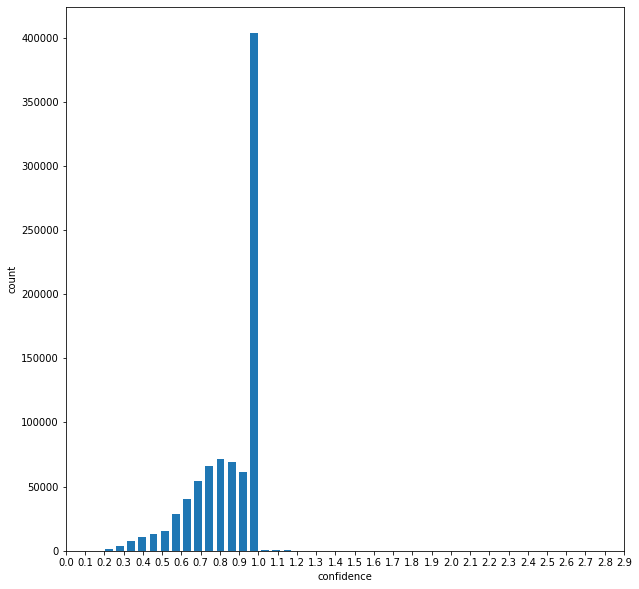

In [23]:
xlim=[0, 2]
plt.rcParams["figure.figsize"] = 10, 10
plot_histogram(dframe = df_agg, column_name='confidence', bin_count=10000,
              xlim=xlim, xticks=np.arange(xlim[0], xlim[1]+1, 0.1))

<BarContainer object of 1000 artists>

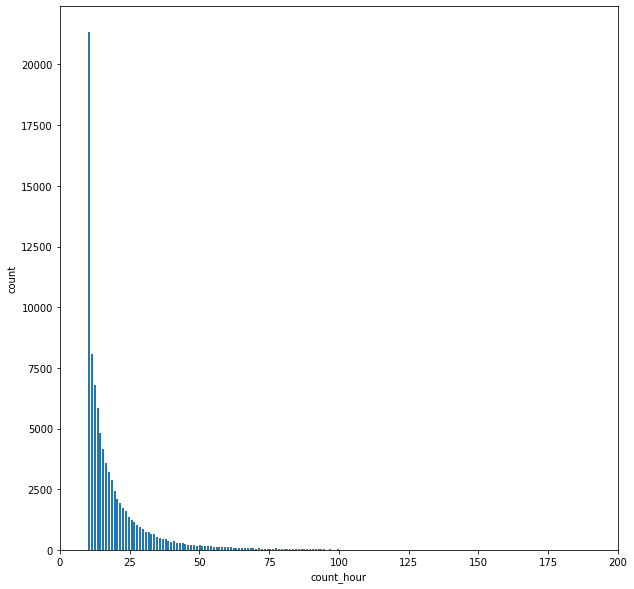

In [24]:
# xlim=[50, 1024]
tst = df_agg[df_agg['count_hour'] >= 10]
plt.rcParams["figure.figsize"] = 10, 10
plot_histogram(dframe = tst, column_name='count_hour', bin_count=1000, xlim=[0, 200])

In [38]:
tst = df_agg[(df_agg['confidence'] >= 0.5) & (df_agg['confidence'] <= 1.5) 
             & (df_agg['count_hour'] >= 10)]
tst.head()

,from_node,to_node,from_coord,to_coord,count_all,hour,mean_speed,std_speed,count_hour,P90_speed,confidence,popularity,frequency,color
82,172543,3982589412,"(13.3394369, 52.5663124)","(13.3416607, 52.5664854)",36.0,22,15.454573,1.170597,12,16.723682,0.924113,0.011707,0.333333,"(0.0, 0.8333333333333334, 1.0, 1.0)"
248,172564,21509247,"(13.3277078, 52.5640457)","(13.3279209, 52.5639596)",17.0,13,1.122741,3.550420,10,1.122741,1.000000,0.009756,0.588235,"(0.7685009487666034, 1.0, 0.19924098671726753,..."
354,458322,5887504395,"(13.2823718, 52.5037272)","(13.2825118, 52.5039046)",282.0,5,21.144241,6.782860,33,25.232844,0.837965,0.032195,0.117021,"(0.0, 0.0, 1.0, 1.0)"
355,458322,5887504395,"(13.2823718, 52.5037272)","(13.2825118, 52.5039046)",282.0,6,19.119843,3.211158,24,23.122663,0.826888,0.023415,0.085106,"(0.0, 0.0, 0.874331550802139, 1.0)"
356,458322,5887504395,"(13.2823718, 52.5037272)","(13.2825118, 52.5039046)",282.0,7,15.878462,3.109081,27,18.669166,0.850518,0.026341,0.095745,"(0.0, 0.0, 0.927807486631016, 1.0)"


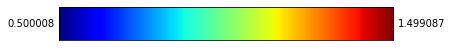

In [30]:
view_colormap('jet', max_value= max(tst['confidence']), min_value=min(tst['confidence']))

/Users/soyella/.local/share/virtualenvs/speed-models-jmP5WddA/lib/python3.7/site-packages/ipykernel_launcher.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  # Remove the CWD from sys.path while we load stuff.


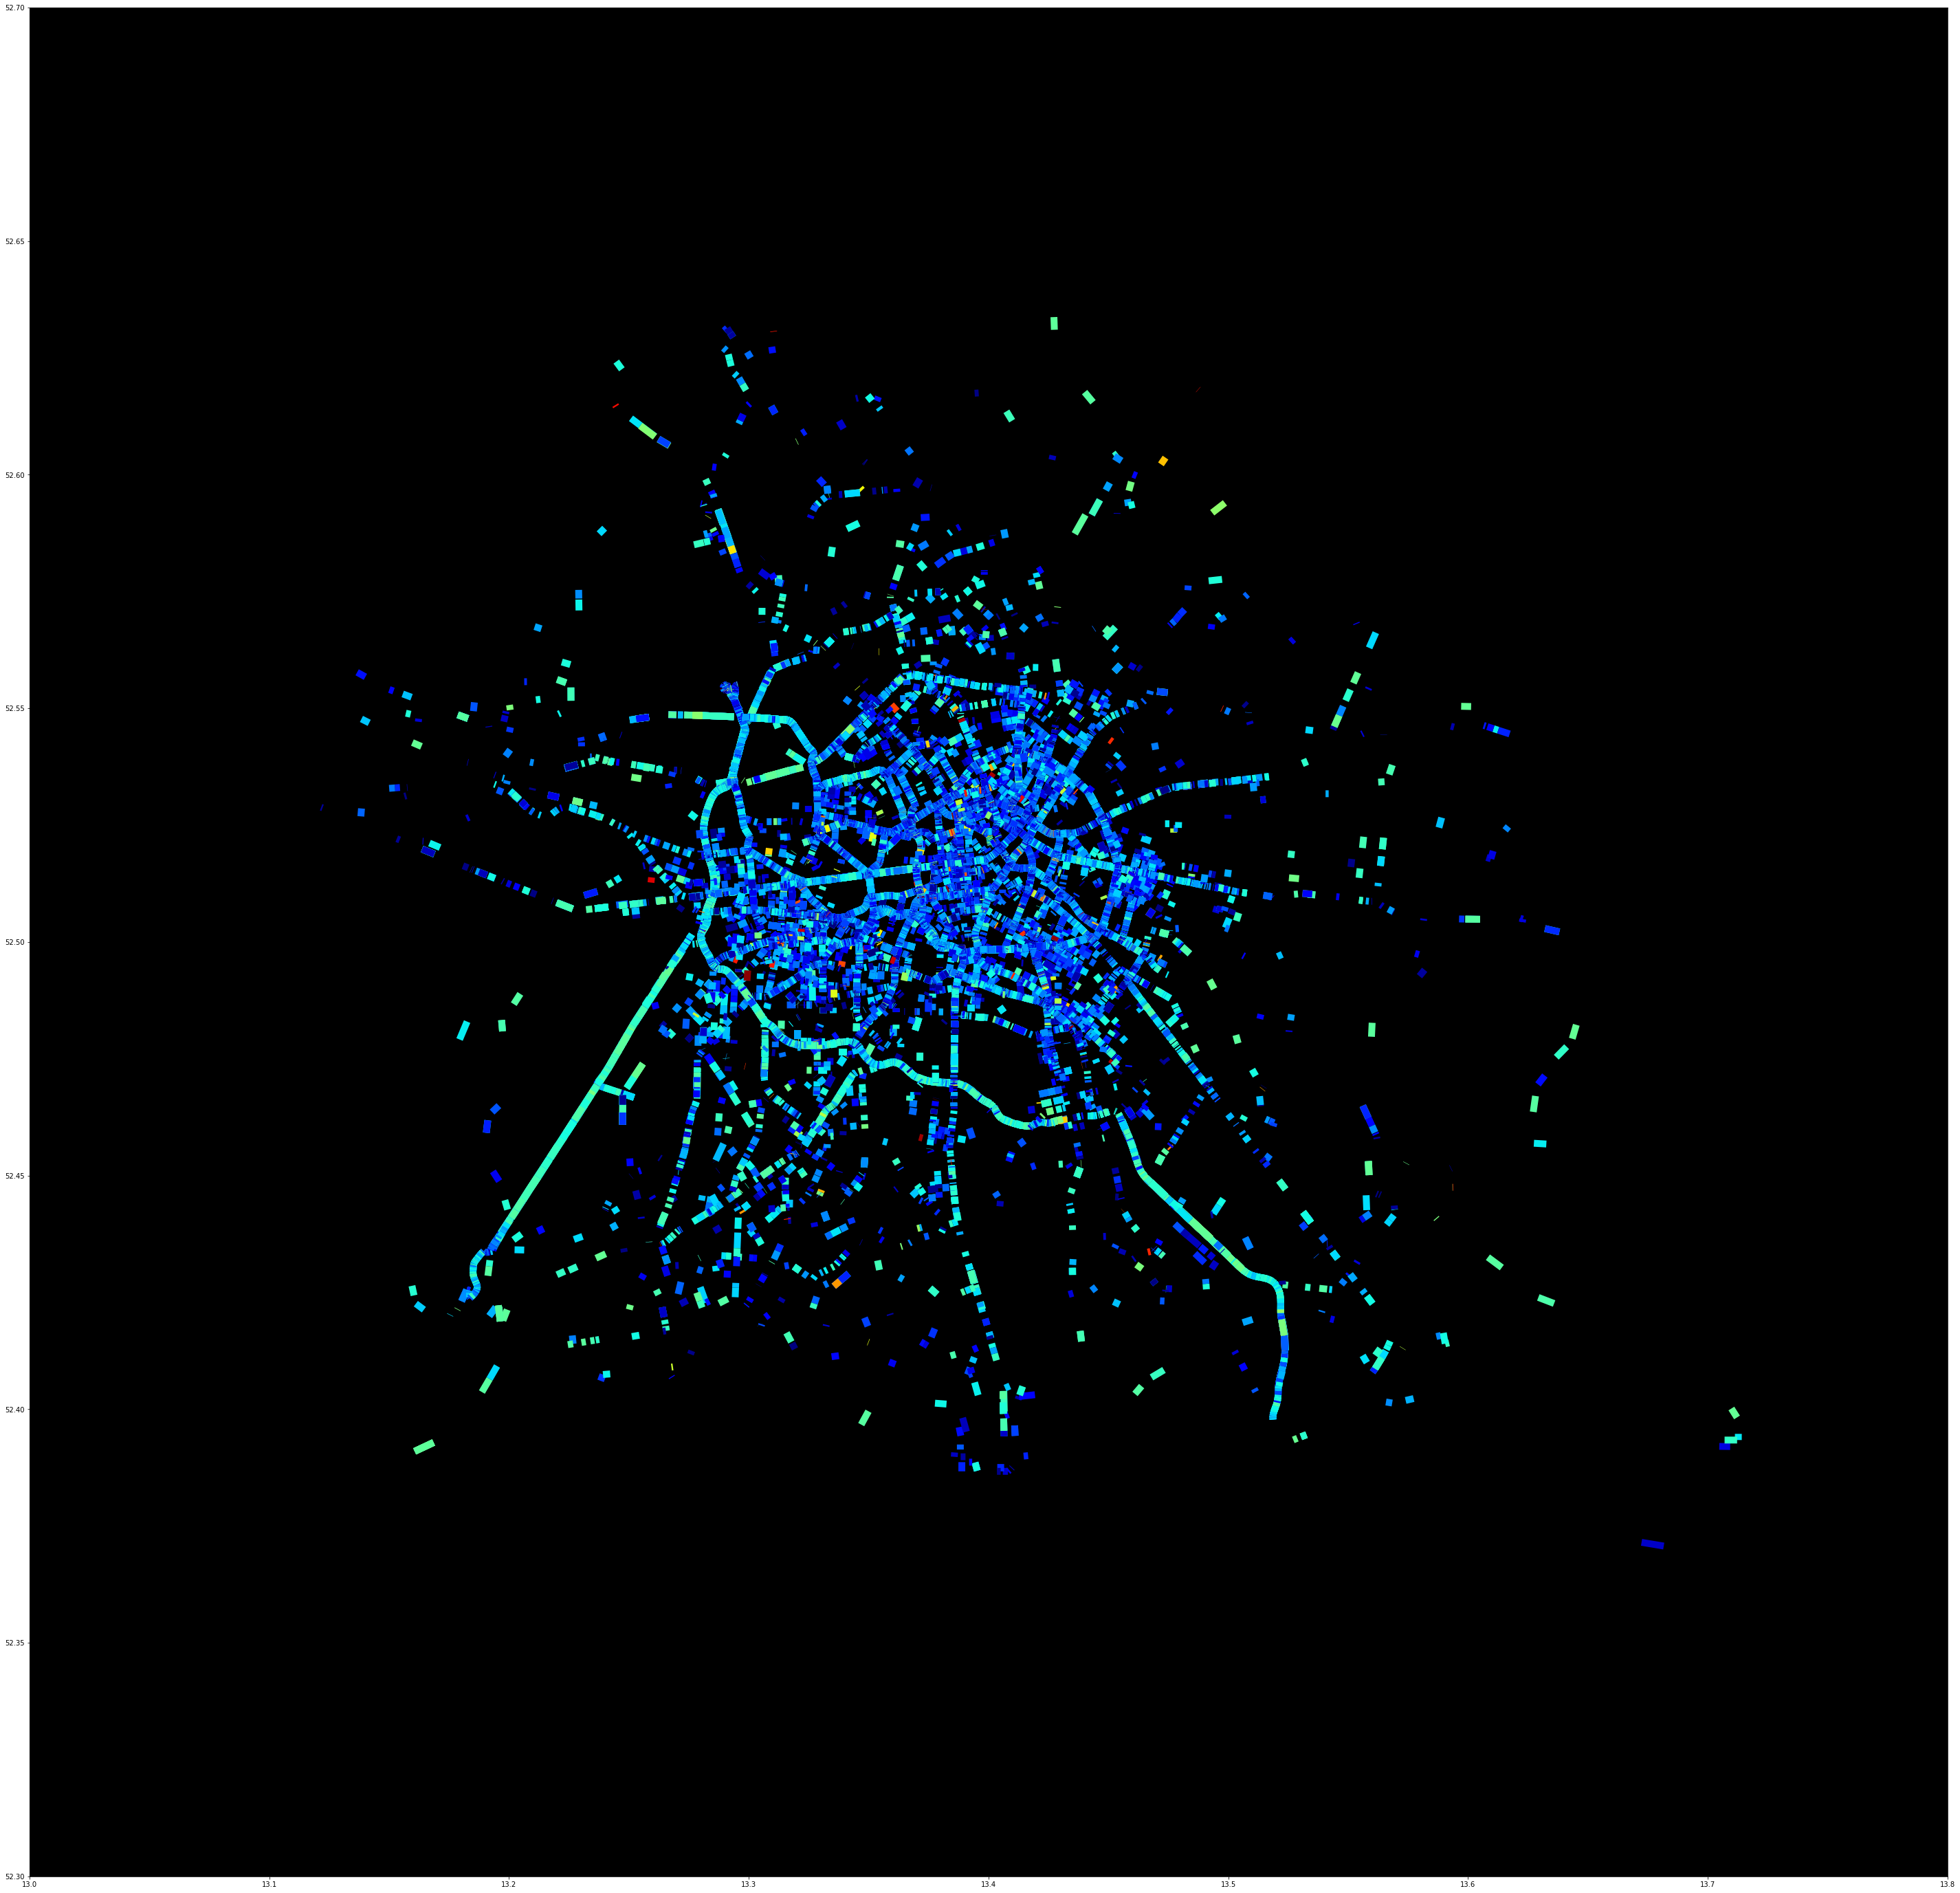

In [31]:
plot_map(tst, 'confidence')

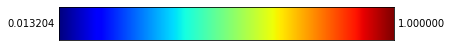

In [39]:
tst_h = tst[tst['hour']==0]
view_colormap('jet', max_value= max(tst_h['frequency']), min_value=min(tst_h['frequency']))

/Users/soyella/.local/share/virtualenvs/speed-models-jmP5WddA/lib/python3.7/site-packages/ipykernel_launcher.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  # Remove the CWD from sys.path while we load stuff.


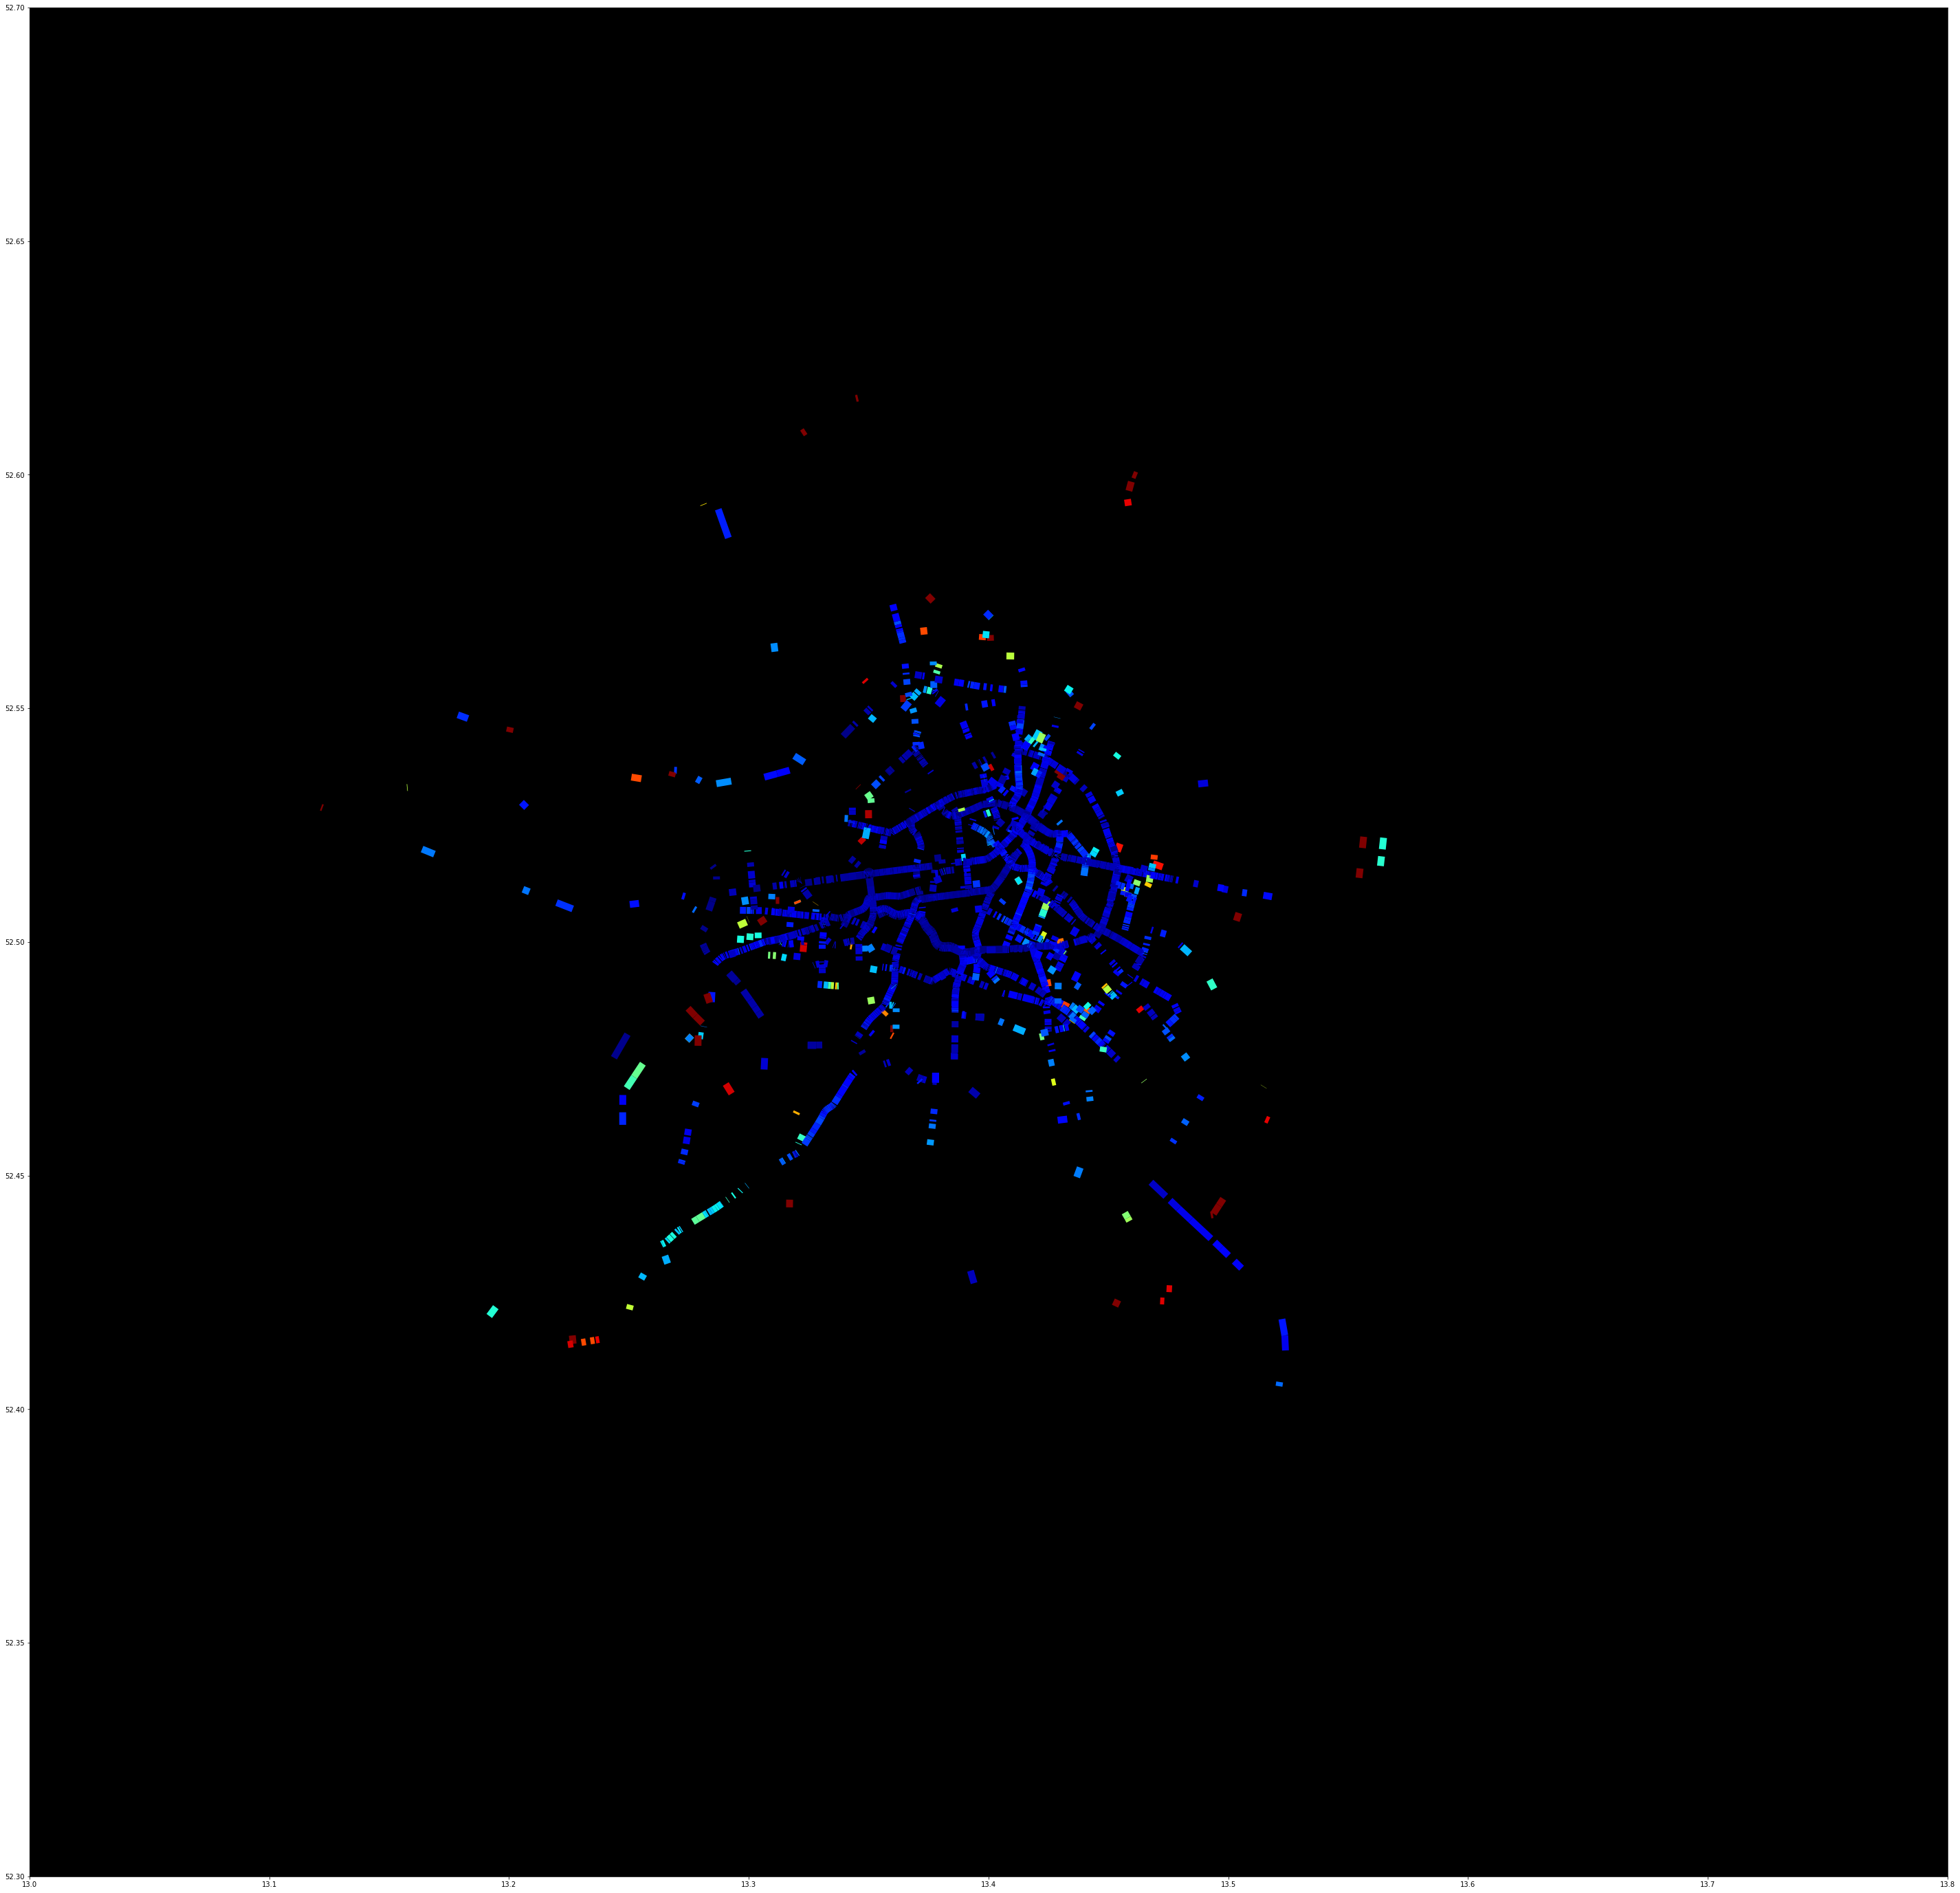

In [40]:
plot_map(tst_h, 'frequency')